In [3]:
import pandas as pd

df_2022 = pd.read_excel("data/all_data_M_2022.xlsx", sheet_name="All May 2022 data")
df_2023 = pd.read_excel("data/all_data_M_2023.xlsx", sheet_name="All May 2023 data")

print("2022:", df_2022.shape)
print("2023:", df_2023.shape)


2022: (409859, 32)
2023: (413327, 32)


In [6]:
import numpy as np

keywords = [
    "data", "software", "developer", "programmer", "database",
    "machine", "research scientist", "statistician",
    "mathematician", "operations research", "computer", "information", "analyst"
]


df_2022["title_low"] = df_2022["OCC_TITLE"].str.lower()
df_2023["title_low"] = df_2023["OCC_TITLE"].str.lower()

mask_2022 = df_2022["title_low"].apply(lambda x: any(kw in x for kw in keywords))
mask_2023 = df_2023["title_low"].apply(lambda x: any(kw in x for kw in keywords))

subset_2022 = df_2022[mask_2022].copy()
subset_2023 = df_2023[mask_2023].copy()

In [7]:
titles_2022 = set(subset_2022["OCC_TITLE"].unique())
titles_2023 = set(subset_2023["OCC_TITLE"].unique())

new_titles_2023 = titles_2023 - titles_2022

print(f"New AI/Data/Software-related occupations in 2023: ({len(new_titles_2023)})")

for title in sorted(new_titles_2023):
    print("*", title)

New AI/Data/Software-related occupations in 2023: (0)


**Challenge Step 1: Searching for New AI-Related Occupation in 2023**

As part of the challenge, it was explored whether any new AI/Data/Software-related occupations were introduced in the 2023 dataset that were not present in 2022.
To do this, it was used a keyword-based filter to isolate relevant occupations and compared unique job titles across both years.

**Results:**
No new AI/Data/Software-related occupations were found in 2023 that were not already listed in 2022.

In [9]:
subset_2022["TOT_EMP"] = pd.to_numeric(subset_2022["TOT_EMP"], errors="coerce")
subset_2023["TOT_EMP"] = pd.to_numeric(subset_2023["TOT_EMP"], errors="coerce")

emp_2022 = (
    subset_2022.groupby("OCC_TITLE")["TOT_EMP"]
    .sum(min_count=1)
    .reset_index()
    .rename(columns={"TOT_EMP": "EMP_2022"})
)

emp_2023 = (
    subset_2023.groupby("OCC_TITLE")["TOT_EMP"]
    .sum(min_count=1)
    .reset_index()
    .rename(columns={"TOT_EMP": "EMP_2023"})
)


merged = pd.merge(emp_2022, emp_2023, on="OCC_TITLE", how="outer")


merged["EMP_DIFF"] = merged["EMP_2023"] - merged["EMP_2022"]
merged["PERCENT_CHANGE"] = (merged["EMP_DIFF"] / merged["EMP_2022"]) * 100


top_change = merged.sort_values("EMP_DIFF", ascending=False)

top_change.head(10)

,OCC_TITLE,EMP_2022,EMP_2023,EMP_DIFF,PERCENT_CHANGE
21,Computer and Mathematical Occupations,36257420.0,37505170.0,1247750.0,3.441365
87,Software Developers,10834600.0,11673340.0,838740.0,7.741310
20,Computer and Information Systems Managers,6682660.0,7402820.0,720160.0,10.776547
11,Computer Occupations,24898450.0,25604640.0,706190.0,2.836281
89,"Software and Web Developers, Programmers, and ...",10625100.0,11274000.0,648900.0,6.107237
61,Market Research Analysts and Marketing Special...,9816130.0,10414040.0,597910.0,6.091097
30,Data Scientists,1988020.0,2420420.0,432400.0,21.750284
60,Management Analysts,10259790.0,10585500.0,325710.0,3.174626
42,Financial and Investment Analysts,2082530.0,2323340.0,240810.0,11.563339
50,Industrial Machinery Mechanics,2731620.0,2915400.0,183780.0,6.727876


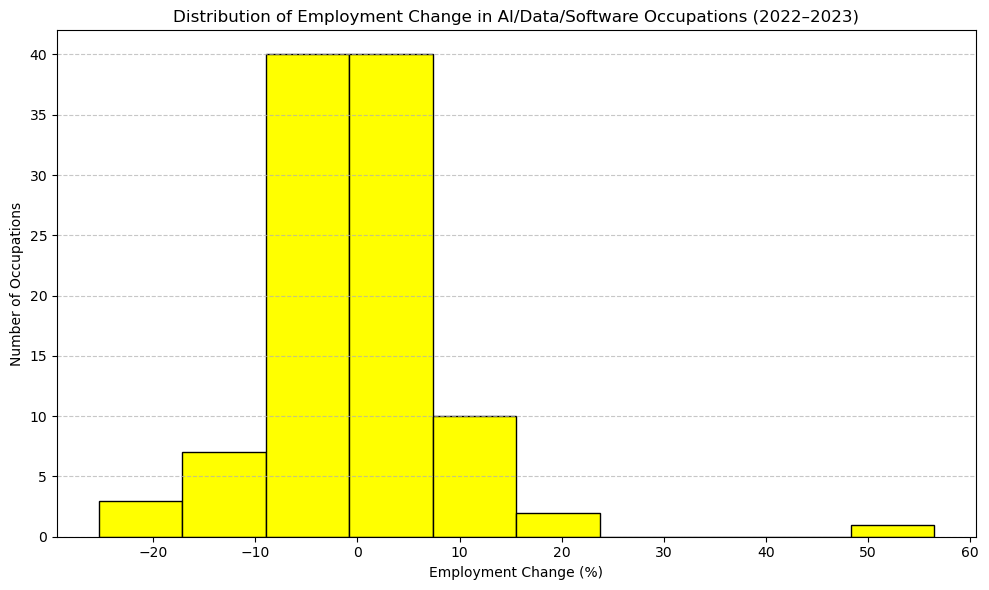

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(merged["PERCENT_CHANGE"].dropna(), bins=10, color="yellow", edgecolor="black")

plt.title("Distribution of Employment Change in AI/Data/Software Occupations (2022–2023)")
plt.xlabel("Employment Change (%)")
plt.ylabel("Number of Occupations")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(r"C:\Users\Clara\Documents\NetBeansProjects\bsc-4th-data-visualisation-2022475\figures\V5_hist_employment.png", dpi=200, bbox_inches="tight")
plt.show()

**Objective:**
Show the percentage changes in employment for AI/Data/Software occupations between 2022 and 2023. How many occupations experienced increases or decreases in workforce size over the year.

**Why this chart type:**
A histogram is good for visualizing the frequency of numerical values ​​within a continuous range. In this case, it clearly illustrates how changes in employment are distributed.

**WHat I learned:**
Looking at this chart, it seen that most technology-related occupations didn't change dramatically between 2022 and 2023; many remained relatively stable. Still, some jobs grew or declined more noticeably, which could indicate shifts in demand for specific skills or areas.